# Exploratory data analysis of LNDb

This section looks at the LNDb training annotations before we commit to any pipeline decision. Every plot is followed by a short discussion, because we believe that most of these numbers will feed straight into choices we still have to make: the patch size, whether to resample the scans, how to build the final malignancy label and how to evaluate the model.

The main table is lndb_processado.csv, produced in explorar_lndb.ipynb. It has one row per finding marked by one radiologist, 1527 rows in total. Its diametro_mm column was recalculated from the segmentation volume with nodEqDiam and is only empty for non-nodules, which are never segmented. The setup cell below checks both things again, so the rest of the notebook fails loudly if the file is ever regenerated wrongly. The raw LNDb files are found with the same encontrar_ficheiro helper used in explorar_lndb.ipynb, so nothing depends on the exact folder layout under ../data.

In [ ]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def encontrar_ficheiro(nome_ficheiro, pasta_base="../data"):
    resultados = list(Path(pasta_base).rglob(nome_ficheiro))
    if not resultados:
        raise FileNotFoundError(f"Ficheiro '{nome_ficheiro}' não foi encontrado em '{pasta_base}'.")
    return str(resultados[0])


df = pd.read_csv(encontrar_ficheiro("lndb_processado.csv", pasta_base="."))
train_nodules = pd.read_csv(encontrar_ficheiro("trainNodules.csv"))
train_nodules_gt = pd.read_csv(encontrar_ficheiro("trainNodules_gt.csv"))
train_cts = pd.read_csv(encontrar_ficheiro("trainCTs.csv"))
acq = pd.read_csv(encontrar_ficheiro("LNDbAcqParams.csv"))

# lndb_processado.csv came from a positional join with trainNodules.csv, so the rows should still line up
# We rely on this later to recover the per scan reader index that trainNodules_gt.csv uses
assert len(df) == len(train_nodules)
assert (df[["scan_id", "nodulo_id", "categoria"]].values
        == train_nodules[["LNDbID", "FindingID", "Nodule"]].values).all()

# The diameter has to be filled for every nodule and empty for every non-nodule
assert df.loc[df["categoria"] == 1, "diametro_mm"].notna().all()
assert df.loc[df["categoria"] == 0, "diametro_mm"].isna().all()

nodules = df[df["categoria"] == 1]
print(f"{len(df)} findings, {len(nodules)} of them nodules, over {df['scan_id'].nunique()} scans")


BLUE, ORANGE, GREY, OLIVE = "blue", "orange", "grey", "olive"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "w",
    "grid.linewidth": 0.8,
    "axes.titlesize": 12,
    "axes.titleweight": "normal",
    "figure.dpi": 110,
})

1527 findings, 1033 of them nodules, over 229 scans


## 1. Nodule diameter

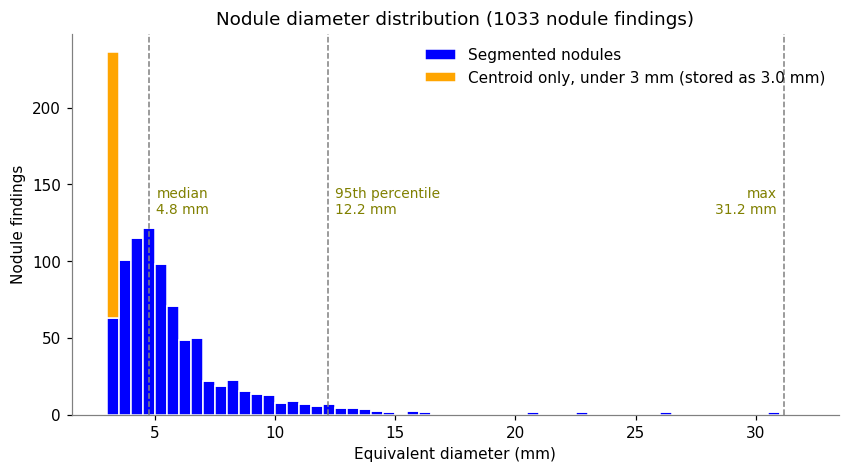

173 of 1033 nodule findings sit exactly on the 3.0 mm placeholder
19 findings above 20 mm, 11 above the 99th percentile


,all nodules,segmented only
count,1033.00,860.00
mean,5.75,6.30
std,3.72,3.85
min,3.00,3.04
50%,4.77,5.15
90%,9.33,9.93
95%,12.21,12.76
99%,24.44,25.26
max,31.15,31.15


In [18]:
# Nodules under 3 mm were only marked with a centroid (LNDb README) and trainNodules.csv gives them the
# volume of a 3 mm sphere, so a diameter of exactly 3.0 mm is a placeholder rather than a measurement
placeholder = np.isclose(nodules["diametro_mm"], 3.0)
diam_all = nodules["diametro_mm"]
diam_seg = diam_all[~placeholder]

p50, p95, dmax = diam_all.median(), diam_all.quantile(0.95), diam_all.max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist([diam_seg, diam_all[placeholder]], bins=np.arange(3, 32.5, 0.5), stacked=True,
        color=[BLUE, ORANGE], edgecolor="white", linewidth=1,
        label=["Segmented nodules", "Centroid only, under 3 mm (stored as 3.0 mm)"])
top = ax.get_ylim()[1]
for value, name, align in [(p50, "median", "left"), (p95, "95th percentile", "left"), (dmax, "max", "right")]:
    ax.axvline(value, color=GREY, linestyle="--", linewidth=1)
    offset = 0.3 if align == "left" else -0.3
    ax.text(value + offset, top * 0.6, f"{name}\n{value:.1f} mm", ha=align, va="top", fontsize=9, color=OLIVE)
ax.set_xlabel("Equivalent diameter (mm)")
ax.set_ylabel("Nodule findings")
ax.set_title(f"Nodule diameter distribution ({len(nodules)} nodule findings)")
ax.legend(frameon=False)
plt.show()

print(f"{placeholder.sum()} of {len(nodules)} nodule findings sit exactly on the 3.0 mm placeholder")
print(f"{(diam_all > 20).sum()} findings above 20 mm, {(diam_all > diam_all.quantile(0.99)).sum()} above the 99th percentile")
pd.DataFrame({
    "all nodules": diam_all.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
    "segmented only": diam_seg.describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
}).round(2)

The first thing the histogram shows is not really about nodule size. 173 of the 1033 nodule findings (17%) have a diameter of exactly 3.0 mm, which is also both the minimum and the 5th percentile. That spike is not a real peak. The LNDb README says nodules smaller than 3 mm were only marked with a centroid and never segmented, and trainNodules.csv gives them the volume of a 3 mm sphere, the same 14.137 mm³ placeholder used for non-nodules. Their true size is somewhere below 3 mm, so the value in the table is a ceiling rather than a measurement. This goes beyond the plot, because these findings also have no segmentation mask, so any feature computed inside the mask, which includes everything pyradiomics extracts, is unavailable for them. Something else looks slightly odd: the smallest segmented nodule has an equivalent diameter of 3.04 mm. The 3 mm rule refers to the largest in plane dimension, so a flat or elongated nodule could qualify and still have an equivalent diameter below 3 mm. Seeing none at all suggests the threshold was applied to the segmented volume in some way. It does not change the analysis, but it is worth knowing if we ever compare these diameters with the ones in the radiology reports.

Once the placeholder is set aside, the nodules are small and the distribution is strongly right skewed. The median is 4.8 mm (5.1 mm for segmented nodules only), and 95% of the findings are below 12.2 mm (12.8 mm for segmented only). The tail is long but thin. Only 19 findings are above 20 mm and the largest is 31.2 mm, so if we had sized things around the maximum we would be designing for a handful of cases.

For the patch size, the 95th percentile is the useful reference, but the patch still has to contain the biggest nodules with some margin, since the margin is exactly where spiculation and lobulation show up. It is also worth remembering that nodEqDiam assumes a sphere, and an elongated nodule extends further than its equivalent diameter along its long axis, so the patch needs some slack on top of these numbers. The default in extractCube is a 51 mm cube. That leaves about 19 mm of context on each side of a 12.2 mm nodule and still about 10 mm around the 31 mm one, so nothing in the training set gets cut. The problem is at the other end. A median 4.8 mm nodule covers less than a tenth of the cube width, and the rest of the patch is surrounding lung, vessels and sometimes chest wall. For a CNN, a patch of around 32 mm would keep the p95 nodule with about 10 mm of margin on each side and give the nodule much more weight in the input. The cost is that roughly 1% of findings, the ones above about 24 mm, would be left with very little surrounding context. That could be handled with a second, larger scale or simply accepted. For radiomics the patch size matters much less, since features are computed inside the mask, as long as the patch fully contains the mask. **With that being said, the real decision here is deciding whether we will use radiomics or deep learning.**

## 2. Voxel spacing across scans

['LNDbID', 'Modality', 'Manufacturer', 'ManufacturerModelName', 'SliceThickness', 'KVP', 'DataCollectionDiameter', 'ReconstructionDiameter', 'DistanceSourceToDetector', 'DistanceSourceToPatient', 'GantryDetectorTilt', 'TableHeight', 'RotationDirection', 'ExposureTime', 'XRayTubeCurrent', 'Exposure', 'FilterType', 'ConvolutionKernel', 'SamplesPerPixel', 'PhotometricInterpretation', 'PixelSpacing']
["['0.607421875', '0.607421875']", "['0.724609375', '0.724609375']", "['0.74609375', '0.74609375']"]
z spacing read from 294 scan headers


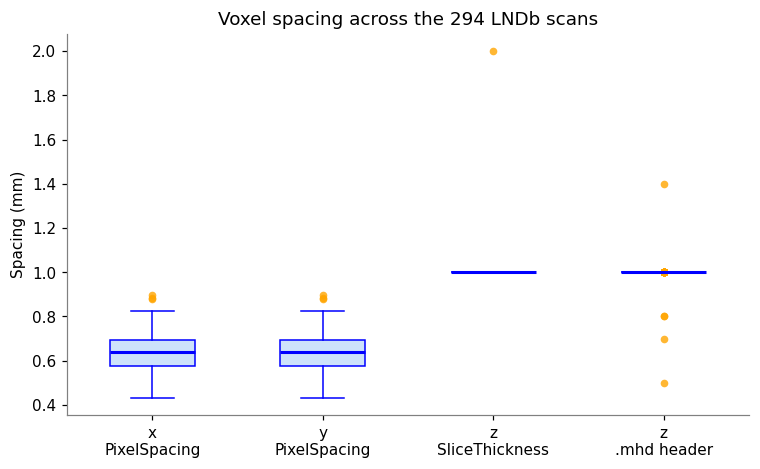

       spacing_x  spacing_y  SliceThickness  spacing_z_header
count    294.000    294.000         294.000           294.000
mean       0.632      0.632           1.003             0.997
std        0.088      0.088           0.058             0.044
min        0.433      0.433           1.000             0.500
25%        0.574      0.575           1.000             1.000
50%        0.640      0.640           1.000             1.000
75%        0.691      0.691           1.000             1.000
max        0.895      0.895           2.000             1.400
Largest x/y difference within a scan: 0.0005 mm
 LNDbID  SliceThickness  spacing_z_header    ManufacturerModelName
    115               1          0.700000 SOMATOM Definition Flash
    209               1          0.500000            SOMATOM go.Up
    268               2          1.400000 SOMATOM Definition Flash
    270               1          0.800062            SOMATOM go.Up
    284               1          0.800000 SOMATOM Definitio

In [19]:
# Check the real column names instead of assuming SpacingX, SpacingY and SpacingZ exist
print(acq.columns.tolist())
print(acq["PixelSpacing"].head(3).tolist())

# In plane spacing comes as the DICOM PixelSpacing string "[row spacing, column spacing]", so [y, x]
pixel_spacing = acq["PixelSpacing"].apply(ast.literal_eval).apply(lambda v: [float(x) for x in v])
acq["spacing_y"] = pixel_spacing.str[0]
acq["spacing_x"] = pixel_spacing.str[1]

# Along z the file only has SliceThickness, which is not the same thing as the distance between slices.
# The actual slice interval is in each .mhd header (ElementSpacing, in x y z order), and reading the
# header text is enough, there is no need to load the volumes.
z_header = {}
for mhd_path in Path("../data").rglob("LNDb-*.mhd"):
    scan_id = mhd_path.stem.replace("LNDb-", "")
    if not scan_id.isdigit() or int(scan_id) in z_header:  # skips masks and duplicate copies of a scan
        continue
    for line in mhd_path.read_text().splitlines():
        if line.startswith("ElementSpacing"):
            z_header[int(scan_id)] = float(line.split("=")[1].split()[2])
acq["spacing_z_header"] = acq["LNDbID"].map(z_header)
print(f"z spacing read from {len(z_header)} scan headers")

columns = ["spacing_x", "spacing_y", "SliceThickness", "spacing_z_header"]
labels = ["x\nPixelSpacing", "y\nPixelSpacing", "z\nSliceThickness", "z\n.mhd header"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([acq[c].dropna() for c in columns], tick_labels=labels, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=5, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.8))
ax.set_ylabel("Spacing (mm)")
ax.set_title(f"Voxel spacing across the {len(acq)} LNDb scans")
plt.show()

print(acq[columns].describe().round(3))
print("Largest x/y difference within a scan:", (acq["spacing_x"] - acq["spacing_y"]).abs().max().round(4), "mm")

odd_z = acq[~np.isclose(acq["spacing_z_header"], 1.0, atol=0.01)]
print(odd_z[["LNDbID", "SliceThickness", "spacing_z_header", "ManufacturerModelName"]].to_string(index=False))
print("of which in the training set:", odd_z["LNDbID"].isin(train_cts["LNDbID"]).sum())

anisotropy = acq["spacing_z_header"] / acq["spacing_x"]
print(f"z / x spacing ratio: median {anisotropy.median():.2f}, from {anisotropy.min():.2f} to {anisotropy.max():.2f}")
print(acq["ManufacturerModelName"].value_counts().to_string())

The file itself was the first surprise. LNDbAcqParams.csv has no SpacingX, SpacingY or SpacingZ columns. The in plane spacing is a single PixelSpacing column holding a two element list stored as text, and along z there is only SliceThickness. Slice thickness and slice spacing are different DICOM quantities, because slices can be reconstructed with overlap, so for z I also read ElementSpacing from each .mhd header. That is what utils.readMhd returns and what the rest of the pipeline actually uses.

In plane, x and y are the same within each scan (the largest difference is below 0.001 mm), but they vary a lot between scans, from 0.43 mm to 0.89 mm with a median of 0.64 mm. With a fixed 512 by 512 matrix, the pixel size follows the reconstruction field of view, **which is adjusted to each patient, so this variation is mostly about body size and not about different protocols.** Along z the picture is the opposite. SliceThickness is 1 mm in 293 of the 294 scans, and the header spacing is 1 mm in 289. The five exceptions (0.5, 0.7, 0.8, 0.8 and 1.4 mm) are all training scans, and only one of them, the 1.4 mm scan reconstructed with 2 mm slices, would be caught by looking at SliceThickness. The other four would go unnoticed if we trusted the CSV, which is a good reason to always take spacing from the image header. All the scans come from three Siemens models, so the acquisition is fairly homogeneous overall, which matches what was noted about LNDb in explorar_lndb.ipynb.

The consequence is that the voxels are anisotropic in practically every scan. The z spacing is typically 1.55 times the in plane spacing and up to 2.3 times, and in the one scan with 0.5 mm slices it goes the other way. **Without resampling, a 6 mm nodule is about 14 pixels wide in one scan and 7 in another, and texture features that compare neighbouring voxels (GLCM and similar) would be mixing different physical distances depending on direction and on the scan.** So resampling to a common isotropic spacing before feature extraction makes sense, and it is also what the IBSI guidelines recommend for 3D radiomics. The harder question is the target. Resampling to 1 mm would throw away in plane resolution in almost every scan, and for the many nodules between 3 and 5 mm that leaves only a few voxels per axis. Something close to the median in plane spacing, around 0.6 to 0.7 mm, seems a better compromise. Upsampling along z does not add information, but it keeps the geometry consistent. extractCube already does this implicitly: it takes a 51 mm cube and resizes it to 80 voxels, an isotropic grid of about 0.64 mm. If we also use pyradiomics, resampledPixelSpacing should be set to the same value so both paths agree. Resampling does not solve everything, though. The reconstruction kernel also varies (mostly Br64f and B50f, with some I50f iterative reconstructions), and kernel differences affect texture features at least as much as spacing does. **We now have to understand if there is the need to minimise this problem or if it is a limitation to identify.**

Informação científica: https://ibsi.readthedocs.io/en/latest/02_Image_processing.html

Confirmação científica da ideia que propomos: https://ibsi.readthedocs.io/en/latest/ 

## 3. Malignancy label coverage

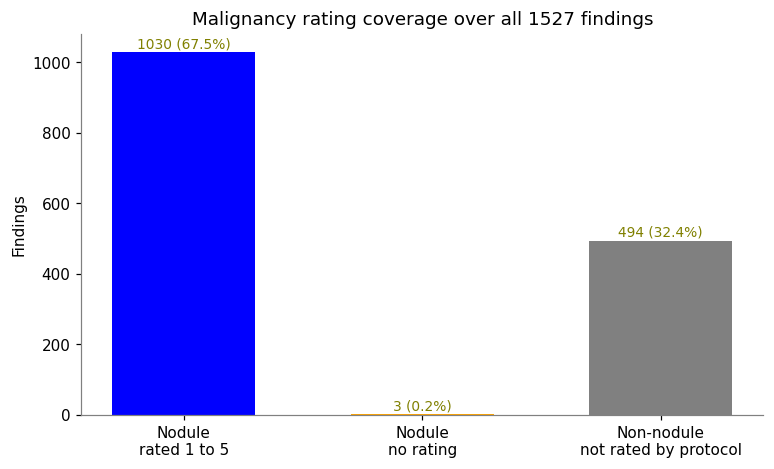

 scan_id  nodulo_id  radiologo_id  diametro_mm
      85          1             1     3.334297
     121          5             1     4.659270
     122          2             1     4.929141
Nodule coverage: 99.7%
Rated nodules without a mask (under 3 mm): 173
Rated nodules with a mask: 857


In [20]:
# lndb_processado.csv stores a malignancy of 0 (not filled in) as NaN
rated = df["malignidade_rating"].notna()
is_nodule = df["categoria"] == 1
assert not (rated & ~is_nodule).any()  # no non-nodule should carry a rating

coverage = pd.Series({
    "Nodule\nrated 1 to 5": (rated & is_nodule).sum(),
    "Nodule\nno rating": (~rated & is_nodule).sum(),
    "Non-nodule\nnot rated by protocol": (~rated & ~is_nodule).sum(),
})
assert coverage.sum() == len(df)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(coverage.index, coverage.values, width=0.6, color=[BLUE, ORANGE, GREY])
for bar, n in zip(bars, coverage.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({n / len(df):.1%})", ha="center", fontsize=9, color=OLIVE)
ax.set_ylabel("Findings")
ax.set_title(f"Malignancy rating coverage over all {len(df)} findings")
plt.show()

print(df.loc[~rated & is_nodule, ["scan_id", "nodulo_id", "radiologo_id", "diametro_mm"]].to_string(index=False))
has_mask = ~np.isclose(df["diametro_mm"], 3.0) & is_nodule
print(f"Nodule coverage: {(rated & is_nodule).sum() / is_nodule.sum():.1%}")
print(f"Rated nodules without a mask (under 3 mm): {(rated & is_nodule & ~has_mask).sum()}")
print(f"Rated nodules with a mask: {(rated & has_mask).sum()}")

Across all 1527 findings, about a third have no malignancy rating because the LNDb protocol only asks for a centroid on non-nodules, so there is nothing to recover there. **Of the 1033 nodule findings, 1030 are rated and only 3 are missing, all three from radiologist R1, in scans 85, 121 and 122. Coverage for nodules is 99.7%.**

Two practical points remain. The three unrated nodules are too few to be worth imputing and can simply be dropped from the classification set. More importantly, having a rating does not mean a finding is usable by every part of the pipeline. 173 of the rated nodules are the under 3 mm findings from the diameter plot, which have a label but no mask. Only 857 rated nodule findings come with a segmentation, and if features are extracted from masks that is the real size of the labelled set. The non-nodules should not be relabelled as malignancy 1 to fill the gap either. A non-nodule is a different kind of finding, not a very benign nodule, and mixing them in would teach the classifier the wrong thing.

## 4. Agreement between radiologists

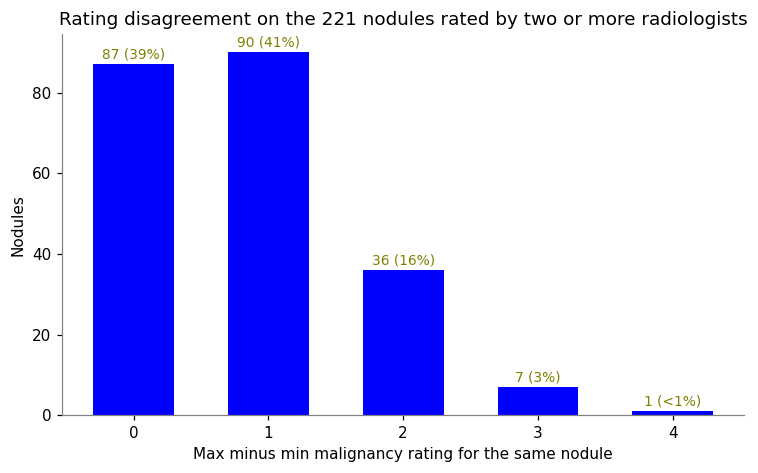

765 unique rated nodules, 221 rated by more than one radiologist
Range of 2 or more: 44 (20%)
Rated 1 to 2 by one reader and 4 to 5 by another: 21
readers who found it    1    2   3
readers of the scan               
1                     162    0   0
2                     233  112   0
3                     152   65  44
              count  mean
radiologo_id             
1               278  2.25
2               119  2.09
3               105  1.57
4               227  2.72
5               301  2.18
                 mean  median  max
label 4 or more    20      20   58
label 2 or less    99     100   81
non integer       101      78    0


In [21]:
# trainNodules_gt.csv has one row per lesion after merging readers. RadID and RadFindingID are comma
# separated lists with the per scan reader index and the matching FindingID in trainNodules.csv,
# so each lesion is expanded into its individual readings and each reading's rating is looked up.
readings = train_nodules[["LNDbID", "RadID", "FindingID"]].copy()
readings["malignancy"] = df["malignidade_rating"].values
readings["diametro_mm"] = df["diametro_mm"].values
readings = readings.set_index(["LNDbID", "RadID", "FindingID"])

rows = []
for lesion_id, lesion in train_nodules_gt[train_nodules_gt["Nodule"] == 1].iterrows():
    for rad, finding in zip(str(lesion["RadID"]).split(","), str(lesion["RadFindingID"]).split(",")):
        rows.append((lesion_id, lesion["LNDbID"], int(rad), int(finding)))
lesion_readings = pd.DataFrame(rows, columns=["lesion", "LNDbID", "RadID", "FindingID"])
lesion_readings = lesion_readings.join(readings, on=["LNDbID", "RadID", "FindingID"])
assert lesion_readings["diametro_mm"].notna().all()  # every reading was matched to a nodule row

per_lesion = (lesion_readings.dropna(subset=["malignancy"])
              .groupby("lesion")["malignancy"].agg(["count", "min", "max", "mean", "median"]))
multi = per_lesion[per_lesion["count"] >= 2].copy()
multi["range"] = (multi["max"] - multi["min"]).astype(int)

counts = multi["range"].value_counts().reindex(range(5), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, counts.values):
    share = f"{n / len(multi):.0%}" if n / len(multi) >= 0.01 else "<1%"
    ax.text(bar.get_x() + bar.get_width() / 2, n + 1.5, f"{n} ({share})", ha="center", fontsize=9, color=OLIVE)
ax.set_xlabel("Max minus min malignancy rating for the same nodule")
ax.set_ylabel("Nodules")
ax.set_title(f"Rating disagreement on the {len(multi)} nodules rated by two or more radiologists")
plt.show()

print(f"{len(per_lesion)} unique rated nodules, {len(multi)} rated by more than one radiologist")
print(f"Range of 2 or more: {(multi['range'] >= 2).sum()} ({(multi['range'] >= 2).mean():.0%})")
print("Rated 1 to 2 by one reader and 4 to 5 by another:", ((multi["min"] <= 2) & (multi["max"] >= 4)).sum())

# Detection agreement: how many of the scan's readers found each nodule
detection = train_nodules_gt[train_nodules_gt["Nodule"] == 1].merge(train_cts, on="LNDbID")
print(pd.crosstab(detection["RadN"], detection["AgrLevel"],
                  rownames=["readers of the scan"], colnames=["readers who found it"]))

# Reader effect on the ratings
print(nodules.groupby("radiologo_id")["malignidade_rating"].agg(["count", "mean"]).round(2))

# How the aggregation rule changes the label of the multi reader nodules
print(pd.DataFrame({rule: {"label 4 or more": (multi[rule] >= 4).sum(),
                           "label 2 or less": (multi[rule] <= 2).sum(),
                           "non integer": (multi[rule] % 1 != 0).sum()}
                    for rule in ["mean", "median", "max"]}))

Of the 765 unique nodules with at least one rating, only 221 were rated by more than one radiologist, so this histogram describes less than a third of the data. Within those, agreement is reasonable but far from perfect. 87 nodules (39%) got exactly the same rating from everyone, and another 90 (41%) differ by one point, which on a subjective 1 to 5 scale is close to noise. **The remaining 20% differ by two points or more, and 21 nodules were called benign (1 or 2) by one reader and suspicious (4 or 5) by another.** For those, the binary label depends entirely on how we aggregate.

The histogram also understates the real disagreement, because it only includes nodules that more than one reader actually found. In scans read by two radiologists, 233 nodules were found by only one of them and 112 by both. In scans read by three, only 44 of 261 nodules were found by all three. **Radiologists disagree far more on whether a nodule is there than on how malignant it looks.** The same goes for nodule versus non-nodule: trainNodules_gt.csv never merges a nodule call with a non-nodule call, so that kind of disagreement cannot even be measured from this file. **There is also a clear reader effect. R3 has a mean rating of 1.57 and R4 of 2.72, and R4 alone gave 95 of the 262 threes. Since 71% of nodules have a single reader, their label partly reflects who happened to read the scan, and no aggregation rule can correct for that.**

On aggregation, the choice is less open than it looks. With two readers the median is just the mean, so the two only differ on the 44 nodules with three readers, and the counts barely move (20 nodules at 4 or above with either rule). The mean does produce half values in 101 of the 221 cases, so the binarisation threshold has to be stated explicitly, especially around 3. The maximum is the option that really changes things. It raises the multi reader nodules labelled 4 or 5 from 20 to 58, almost three times as many positives in that subset. **Clinically it is the cautious choice, since one suspicious read is enough to flag a nodule, but it also amplifies reader bias, and it gives nodules seen by three readers more chances to be labelled positive than nodules seen by one, which is an artefact of the annotation process and not of the nodule.** Therefore the mean is the more defensible default, with an explicit threshold, and the maximum is worth keeping as a sensitivity check to see whether the results hold under a more conservative labelling. Training on individual readings without aggregating is another option, but then the split must be done by scan (trainFolds.csv already gives scan level folds) so that the same nodule never appears in both training and test.

## 5. Malignancy class distribution

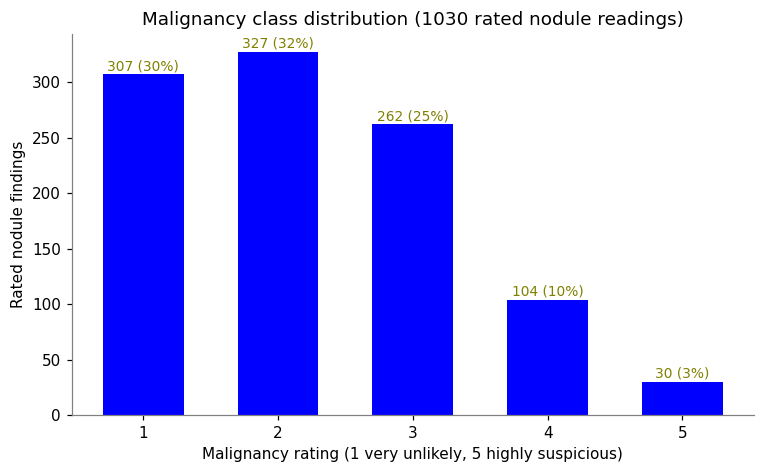

Always predicting the majority class, 5 classes: 31.7% accuracy
Always predicting benign, binary without the 3s: 82.6% accuracy
Always predicting benign, binary with 3 counted as benign: 87.0% accuracy
mean
1    230
2    279
3    182
4     60
5     14
Name: count, dtype: int64
Share of 4 and 5 with a mask: 15.5% of 857


In [22]:
class_counts = nodules["malignidade_rating"].value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0]).astype(int)
total = class_counts.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([1, 2, 3, 4, 5], class_counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 4, f"{n} ({n / total:.0%})", ha="center", fontsize=9, color=OLIVE)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Malignancy rating (1 very unlikely, 5 highly suspicious)")
ax.set_ylabel("Rated nodule findings")
ax.set_title(f"Malignancy class distribution ({total} rated nodule readings)")
plt.show()

benign, indeterminate, suspicious = class_counts[[1.0, 2.0]].sum(), class_counts[3.0], class_counts[[4.0, 5.0]].sum()
print(f"Always predicting the majority class, 5 classes: {class_counts.max() / total:.1%} accuracy")
print(f"Always predicting benign, binary without the 3s: {benign / (benign + suspicious):.1%} accuracy")
print(f"Always predicting benign, binary with 3 counted as benign: {(benign + indeterminate) / total:.1%} accuracy")

# Same distribution per unique nodule, averaging readers and rounding to the nearest class
print(pd.cut(per_lesion["mean"], [0, 1.5, 2.5, 3.5, 4.5, 5], labels=[1, 2, 3, 4, 5]).value_counts().sort_index())

# And restricted to readings that have a segmentation
with_mask = nodules[~placeholder]["malignidade_rating"].dropna()
print(f"Share of 4 and 5 with a mask: {(with_mask >= 4).mean():.1%} of {len(with_mask)}")

The distribution is heavily skewed towards the benign end. Ratings 1 and 2 account for 634 of the 1030 rated readings (62%), 3 for 262 (25%), and 4 and 5 together for only 134 (13%). Class 5 has just 30 readings, and after grouping readings by lesion it gets even thinner, with only 14 unique nodules averaging above 4.5. The per reading counts also overstate how much data each class has, since the same nodule can appear up to three times.

This backs up our decision not to rely on accuracy alone, and the numbers make the argument on their own. A model that always predicts benign would get a nhigh value of accuracy while missing every suspicious nodule. Accuracy would reward exactly the behaviour which is not our main goal. **Recall on the suspicious class, balanced accuracy, F1 and ROC AUC say much more, and with this few positives the precision recall curve is more honest than ROC, together with the confusion matrix itself.** If we keep the five classes, they are ordinal, so a weighted kappa would penalise predicting 1 for a 5 more than predicting 4 for a 5, which plain accuracy treats as the same mistake.

Two things should shape the binary definition. First, class 3 is the second largest class and means indeterminate, not malignant. Moving it to either side changes the positive rate a lot, so it needs a deliberate decision, and it is also the class where reader bias is strongest, with R4 contributing over a third of the threes. Second, the 173 findings under 3 mm are almost all 1s and 2s and have no mask. If they are excluded for that reason, the share of 4 and 5 rises from 13% to about 15.5%, so the imbalance is a bit softer on the data we will actually use, but it does not go away. Class weights or resampling during training will still be needed, and the folds should be stratified by class as well as grouped by scan.

## 6. Nodules and non-nodules

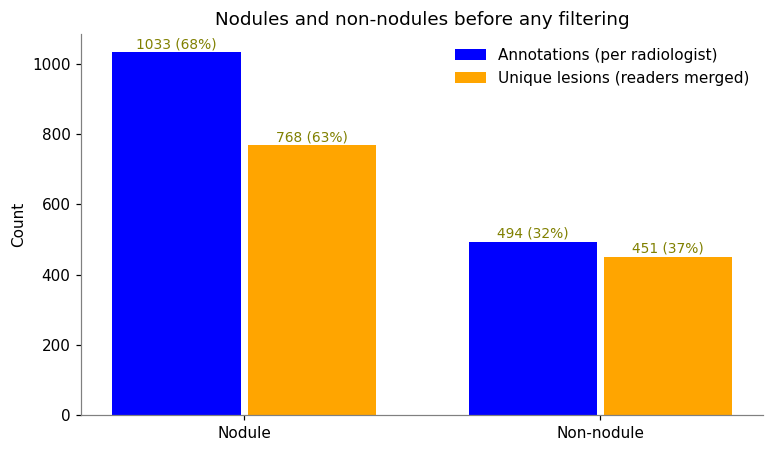

CT scans in LNDb: 294
Training scans: 236 (58 withheld for the challenge test set)
Training scans with at least one annotation: 229
Training scans with at least one nodule: 212
readers per scan
1     59
2    110
3     67
Non-nodule lesions marked by a single reader: 408
Rated, segmented nodules: 857 readings, 622 unique lesions, 204 scans


In [23]:
# Two levels: individual annotations (one row per radiologist and finding) and unique lesions after
# merging readers in trainNodules_gt.csv
per_annotation = df["categoria"].value_counts().reindex([1, 0])
per_lesion_cat = train_nodules_gt["Nodule"].value_counts().reindex([1, 0])

x = np.arange(2)
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, series, color, label in [(-width / 2 - 0.01, per_annotation, BLUE, "Annotations (per radiologist)"),
                                     (width / 2 + 0.01, per_lesion_cat, ORANGE, "Unique lesions (readers merged)")]:
    bars = ax.bar(x + offset, series.values, width, color=color, label=label)
    for bar, n in zip(bars, series.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({n / series.sum():.0%})",
                ha="center", fontsize=9, color=OLIVE)
ax.set_xticks(x, ["Nodule", "Non-nodule"])
ax.set_ylabel("Count")
ax.set_title("Nodules and non-nodules before any filtering")
ax.legend(frameon=False)
plt.show()

print("CT scans in LNDb:", len(acq))
print("Training scans:", len(train_cts), f"({len(acq) - len(train_cts)} withheld for the challenge test set)")
print("Training scans with at least one annotation:", df["scan_id"].nunique())
print("Training scans with at least one nodule:", nodules["scan_id"].nunique())
print(train_cts["RadN"].value_counts().sort_index().rename_axis("readers per scan").rename("scans").to_string())
print("Non-nodule lesions marked by a single reader:",
      (train_nodules_gt.loc[train_nodules_gt["Nodule"] == 0, "RadID"].astype(str).str.count(",") == 0).sum())

# What is left for a malignancy classifier that needs a mask
usable = lesion_readings[lesion_readings["malignancy"].notna() & ~np.isclose(lesion_readings["diametro_mm"], 3.0)]
print(f"Rated, segmented nodules: {len(usable)} readings, {usable['lesion'].nunique()} unique lesions, "
      f"{usable['LNDbID'].nunique()} scans")

Before any filtering, the LNDb training set has 236 CT scans (the other 58 of the 294 were withheld for the challenge test set). 229 of them have at least one annotation and 212 have at least one nodule, so only 7 scans are completely empty. Most scans were read by more than one radiologist: 59 by one, 110 by two and 67 by three.

At the annotation level there are 1527 rows, 1033 nodules (68%) and 494 non-nodules (32%). After merging readers there are 1219 unique lesions, 768 nodules and 451 non-nodules, so the non-nodule share goes up to 37%. The shift makes sense. Nodules are more often marked by several readers.

The main practical point is that 1527 rows are far from 1527 training examples for a malignancy classifier. Taking only nodules leaves 1033 readings, dropping the 3 unrated ones leaves 1030, and if the features need a mask, dropping the under 3 mm findings leaves 857 readings. Grouped by lesion, that becomes 622 unique nodules from 204 patients, and only about 12% of them average above 3.5, which puts them on the suspicious side. At the moment we consider that the non-nodules should not disappear from the project though. 

## Decisions taken

**Aggregate by nodule, not by individual reading.** The same physical nodule can be read by up to three radiologists in LNDb, so treating each reading as its own training example would let a nodule with three readers count three times as much as one with a single reader, and would let the same nodule leak across a train/test split. Therefore, since a decision had to be made regarding this matter we decided to aggregate by nodule. Moreover, to support our decision we also used the fact that the nodule, not the reading, is the clinical unit of analysis: both LNDb and LIDC-IDRI are annotated by having several radiologists independently assess the same lesion precisely so their readings can be pooled into one judgement about it (usar na webgrafia: McNitt-Gray et al., 2007).

**Use the mean, not the max.** Section 4 showed the max is not a neutral choice: it nearly tripled the count of positive multi-reader nodules (20 to 58), and it gives nodules read by three radiologists more chances of ending up positive than nodules read by one, which is an artefact of who happened to read the scan, not a property of the nodule. The mean also absorbs the known reader effect directly (R4 rating far higher on average than R3) instead of letting one biased reader decide the label on their own. It also matches how the LIDC-IDRI literature we compare against later builds its own labels: Causey et al. (2018) assign each nodule "the average of the malignancy ratings assigned by the radiologists who annotated the nodule, rounded to the nearest integer," then drop the resulting class 3 nodules from their binary comparison. Rounding an average to the nearest integer is the same thing as cutting it at 1.5 / 2.5 / 3.5 / 4.5, so their class 3 is our 2.5 to 3.5 indeterminate band; we just keep it as a continuous mean and an explicit band instead of rounding it away. (Talvez explicar esta parte melhor). In conclusion, our understanding of the topic is that the max amplifies reader bias and rewards nodules that happened to be seen by more professionals. With that in mind and also considering the literature cited, we consider the mean to be a better trade-off option.

**The scale is ordinal, and the classes are imbalanced.** Malignancy 1 to 5 is a rating of increasing likelihood, not five unrelated categories, so predicting 1 for a true 5 should count as a worse mistake than predicting 4 for a true 5, something plain accuracy cannot express ( webgrafia Cohen, 1968, on weighted agreement between ordinal ratings). Combined with the idea already shown in section 5, ratings 1 and 2 covering 62% of readings against 13% for 4 and 5, accuracy also rewards a model that always predicts benign, which is exactly the failure mode we want the evaluation to expose rather than hide (He & Garcia, 2009, on why imbalanced problems need metrics beyond accuracy - colocar webgrafia).

**Class 3 cannot be dropped without a deliberate decision.** It is the second largest class, 25% of readings, it is the class most shaped by a single reader's bias (R4 alone gave over a third of all the 3s), and, as we have understood in the literature and explain in the next section in more detail, the literature built specifically around this labelling problem treats discarding it outright as the weaker default rather than the safer one (Lei et al., 2020; Zhang et al., 2022; Baltatzis et al., 2021).

## 7. Formalising the malignancy label per nodule

This section aims to turn the previous discussions into a single table, `nodule_labels`, with one row per unique nodule, and is meant to be aggregated with LIDC.

The table keeps three views of the same rating side by side instead of picking one and throwing the others away.


1 - `malignancy_mean` is the continuous mean malignancy across every radiologist who rated a given nodule, and it is the version we intend to train on. 


2 - `label_ternary` buckets the same mean into benign / indeterminate / malignant at the 2.5 / 3.5. Our goal with this relates more with the possibility of showing results rather than training the model.


3 - `label_binary` is the strict two class view which may be useful to compare with some literature results, for instance. One important aspect we made sure to include was the way to handle the "indeterminate" in order to make sure it was an explicit decision. For indeterminate nodules this column is marked with NaN. This specifically means that if we want to ignore this category for any model we will have to make such decision deliberatly and not something that happens silently.

We are keeping the class 3 nodules in `malignancy_mean` and `label_ternary`, rather than dropping them the way a plain 1-2-vs-4-5 binary pipeline would, because the literature built specifically around this labelling problem treats exclusion as the weaker default, not the safer one. Taking into consideration all that we have learnt about the topic we consider the idea of disconsidering this data.  Work designed around LIDC's "unsure" nodules frames plain exclusion as the problem it exists to solve: existing pipelines "discard unsure nodules and simply deal with a binary classification", which is exactly the data we want to keep, and ordinal regression over the full scale is proposed as the fix (webgrafia Lei et al., 2020). The same critique, together with a demonstration of how much reported performance shifts once excluded nodules are handled differently, appears in Zhang et al. (2022). Separately, and more about the discipline of documenting this decision than about the aggregation itself, a case study built around this exact family of datasets shows that different published sample-selection rules produce subsets of very different difficulty, to the point that "on a more challenging sample selection, on the same database, the more advanced models underperform with respect to very simple baseline methods" (Baltatzis et al., 2021). That is the reason every derived column below is computed explicitly, with its own printed counts, rather than folded into an early filter: whichever threshold ends up used has to be visible and defensible on its own, not an accident of how the table was assembled.

In [ ]:
# One row per unique nodule (train_nodules_gt with Nodule == 1), carrying position, volume, and the
# malignancy statistics already computed per lesion in section 4 (per_lesion). Non-nodules cannot enter
# this table: both per_lesion and the .loc filter below start from Nodule == 1 only.
nodule_labels = (train_nodules_gt.loc[train_nodules_gt["Nodule"] == 1,
                                       ["LNDbID", "FindingID", "x", "y", "z", "Volume"]]
                  .join(per_lesion, how="left")
                  .rename(columns={"mean": "malignancy_mean", "count": "n_raters"}))
nodule_labels.insert(0, "dataset", "LNDb")

assert (train_nodules_gt.loc[nodule_labels.index, "Nodule"] == 1).all()  # non-nodules cannot be in here
n_non_nodule = (train_nodules_gt["Nodule"] == 0).sum()
print(f"{len(nodule_labels)} nodule lesions kept, {n_non_nodule} non-nodule lesions excluded, "
      f"out of {len(train_nodules_gt)} unique lesions in trainNodules_gt.csv")
print(f"{nodule_labels['malignancy_mean'].isna().sum()} nodules have no rated reading and stay unlabelled")

# The 2.5 / 3.5 split already used informally in section 5, made explicit and applied to the continuous
# per-nodule mean rather than to individual readings.
nodule_labels["label_ternary"] = pd.cut(nodule_labels["malignancy_mean"], bins=[0, 2.5, 3.5, 5],
                                        labels=["benign", "indeterminate", "malignant"])

# The strict two class view some baselines will want. Indeterminate nodules get NaN here, not a dropped
# row: nodule_labels keeps every nodule, and excluding the indeterminate band for a given model becomes
# an explicit nodule_labels["label_binary"].notna() filter at that model's own boundary.
nodule_labels["label_binary"] = nodule_labels["label_ternary"].map({"benign": 0, "malignant": 1})

print("\nTernary label:\n", nodule_labels["label_ternary"].value_counts(dropna=False).to_string())
print("\nBinary label (NaN = indeterminate or unrated):\n",
      nodule_labels["label_binary"].value_counts(dropna=False).to_string())

n_rated = nodule_labels["malignancy_mean"].notna().sum()
n_indeterminate = (nodule_labels["label_ternary"] == "indeterminate").sum()
print(f"\n{n_indeterminate} of {n_rated} rated nodules ({n_indeterminate / n_rated:.1%}) sit in the "
      f"indeterminate band; a plain 3-vs-rest exclusion rule would have dropped all of them from training")

nodule_labels.to_csv("lndb_nodule_labels.csv", index_label="lesion")
nodule_labels.head()

The three columns are views of one number, not three different labelling schemes. `malignancy_mean` is what should feed a model whose output also has to serve as the competition's 1 to 5 prediction, since it keeps the full ordinal scale. `label_ternary` and `label_binary` are read off that same number afterwards, purely for reporting: computing balanced accuracy, F1 or a confusion matrix against `label_ternary`, or against `label_binary.notna()` for a stricter two class comparison, gives us numbers that a clinician, or the accuracy and AUC figures quoted in the related work section of the project brief, can actually be read against, without ever having trained on a version of the data missing a quarter of its nodules.

One thing worth checking once this cell has actually run against a consistent `lndb_processado.csv`: 25% of individual readings are rated 3 (section 5), but that reading level share is not the same number as the share of nodules whose `malignancy_mean` lands in the indeterminate band. Averaging pulls single-reader nodules toward whatever that one reader said, so a nodule read once as a 3 stays there, while a nodule read by several radiologists only ends up near 3 if their ratings disagree in a way that happens to average out, or if several of them independently land close to the middle. The count printed above the ternary breakdown is the number that actually matters for deciding how much data an exclusion rule would cost, not the reading level 25%, and it is worth re-checking whenever `per_lesion` changes.


**Scientific basis**
- Lei, Y., Zhu, H., Zhang, J., & Shan, H. (2020). *Meta Ordinal Regression Forest For Learning with Unsure Lung Nodules*. IEEE International Conference on Bioinformatics and Biomedicine (BIBM). https://arxiv.org/abs/2012.03480 — motivates keeping class 3 / "unsure" nodules in training through ordinal regression instead of a binary exclusion rule.
- Zhang, H., Gu, X., Zhang, M., Yu, W., Chen, L., Wang, Z., Yao, F., Gu, Y., & Yang, G.-Z. (2022). *Re-thinking and Re-labeling LIDC-IDRI for Robust Pulmonary Cancer Prediction*. https://arxiv.org/abs/2207.14238 — compares 6 different ways of turning LIDC's average malignancy score into a binary label (excluding the uncertain average outright, or sliding the division threshold across it), and shows the resulting bias toward false positives shrinks but does not disappear as the threshold moves; quantifies the labelling bias this section is designed to avoid.
- Baltatzis, V., Bintsi, K.-M., Le Folgoc, L., Martinez Manzanera, O. E., Ellis, S., Nair, A., Desai, S., Glocker, B., & Schnabel, J. A. (2021). *The Pitfalls of Sample Selection: A Case Study on Lung Nodule Classification*. PRIME, MICCAI 2021. https://arxiv.org/abs/2108.05386 — shows that sample-selection choices on this same family of datasets can outweigh model choice in reported results, which is why every threshold used here is stated and printed explicitly.
- McNitt-Gray, M. F., Armato, S. G., Meyer, C. R., Reeves, A. P., McLennan, G., Pais, R. C., Freymann, J., Brown, M. S., Engelmann, R. M., Bland, P. H., Laderach, G. E., Piker, C., Guo, J., Towfic, Z., Qing, D. P.-Y., Yankelevitz, D. F., Aberle, D. R., van Beek, E. J. R., MacMahon, H., Kazerooni, E. A., Croft, B. Y., & Clarke, L. P. (2007). *The Lung Image Database Consortium (LIDC) Data Collection Process for Nodule Detection and Annotation*. Academic Radiology, 14(12), 1464–1474. Already cited as [MGAM+07] in the project brief; establishes malignancy as a per-radiologist ordinal rating, which is why it is treated as one continuous quantity here rather than a category from the start, and why several independent readers are pooled per nodule rather than kept as separate examples.
- Causey, J. L., Zhang, J., Ma, S., Jiang, B., Qualls, J. A., Politte, D. G., Prior, F., Zhang, S., & Huang, X. (2018). *Highly accurate model for prediction of lung nodule malignancy with CT scans*. Scientific Reports, 8, 9286. Already cited as [CZM+18] in the project brief; builds each nodule's label from "the average of the malignancy ratings assigned by the radiologists who annotated the nodule, rounded to the nearest integer" and excludes the resulting class 3 from its S1-vs-S45 and S12-vs-S45 binary comparisons — the same averaging step used here, with class 3 rounded away instead of kept as an explicit band.
- Cohen, J. (1968). *Weighted kappa: Nominal scale agreement with provision for scaled disagreement or partial credit*. Psychological Bulletin, 70(4), 213–220. https://doi.org/10.1037/h0026256 — supports treating the 1 to 5 malignancy scale as ordinal rather than nominal when scoring agreement or model error.
- He, H., & Garcia, E. A. (2009). *Learning from Imbalanced Data*. IEEE Transactions on Knowledge and Data Engineering, 21(9), 1263–1284. https://doi.org/10.1109/TKDE.2008.239: motivates the move away from accuracy given how skewed the malignancy classes are, first raised in section 5.